# Data 
FROM README.txt

List of Attribute 
    This dataset is designed to support the development of automated classification models for user reviews in telemedicine applications. It also includes additional attributes, such as weight. The list of attributes is shown in the table below. 

Attribute Description 
- platform : Application distributor platform 
- app_name : Application name 
- rating : Application user satisfaction score  
- review : Application user review 
- sentiment : Data label (negative, neutral, positive) 
- weight : User review complexity label (uninformative, informative, complex) 

Value of the Data 
- The Weighted Telemedicine Sentiment Dataset contains 19,680 manually annotated Indonesian-language user reviews from three telemedicine applications, labeled with three sentiment classes (Positive, Neutral, Negative) and a weight attribute (Uninformative, Informative, Complex) indicating review informativeness. 
- The annotation was performed by two annotators following a documented guideline reviewed by a psychology expert, with inter-annotator agreement measured using Cohen's Kappa, which indicated substantial agreement (κ = 0.752), thereby enabling other researchers to assess label reliability. 
- Facilitates and supports experiments in advanced NLP technologies, including BERT, LSTM, and LLMs, such as the user review sentiment classification task. 
- This dataset introduces a weight attribute (Uninformative, Informative, Complex), which adds a crucial secondary dimension. This enables researchers to analyze not only what the user feels but also the substantive value of the review, thereby facilitating more advanced tasks such as Aspect-Based Sentiment Analysis (ABSA). On the other hand, this label can be enabled to curate the data, such as filtering uninformative reviews or studying the characteristics of complex user feedback, while telemedicine providers can use the labeled reviews to examine user-reported service issues. 

Data Annotation 
- The dataset was manually annotated by two annotators 

- A fundamental difference from the previous dataset lies in the manual annotation process, which was validated by Psychology experts, ensuring that the resulting annotations align with scientific psychological principles 

# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## Read CSV File & Initiating EDA

In [2]:
df = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', low_memory=False)
df["orig_id"] = df.index

## A. Data Description

In [3]:
df.head(5)

,platform,app_name,rating,review,sentiment,weight,orig_id
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE,0
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,1
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,2
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE,3
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,4


In [4]:
df['platform'].value_counts()

platform
Play Store    19680
Name: count, dtype: int64

In [5]:
df['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7602
Halodoc: Dokter, Obat & Lab       7295
KlikDokter: Jaga Sehatmu          4783
Name: count, dtype: int64

In [6]:
df['weight'].value_counts()

weight
UNINFORMATIVE    16572
INFORMATIVE       2718
COMPLEX            390
Name: count, dtype: int64

### A.1 Null value & Duplicate detection

In [7]:
df['review_character_length'] = df['review'].str.len()
df['review_word_count'] = df['review'].str.split().str.len()

In [8]:
# Check total duplicates
print(df['review'].str.lower().str.strip().duplicated().sum())

1305


In [9]:
# Check Missing Value
null_reviews = df[df['review'].isna()].copy()
print(f"Total NaN reviews in df: {len(null_reviews)}")

Total NaN reviews in df: 52


In [10]:
# Inspect the metadata of these 52 rows
display(null_reviews[['app_name', 'rating', 'sentiment', 'weight', 'review']])

# Check what was originally written in the raw CSV file
raw = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', 
                        keep_default_na=False, low_memory=False)

# Get the exact strings from the raw file for these 52 row indexes
raw_values = raw.loc[null_reviews.index, 'review']
print("\nExact text in raw CSV for these rows:")
print(raw_values.value_counts(dropna=False))

,app_name,rating,sentiment,weight,review
3390,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,NaN
3458,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,NaN
3482,Alodokter —Chat Bersama Dokter,1,NEGATIVE,UNINFORMATIVE,NaN
3915,"Halodoc: Dokter, Obat & Lab",1,NEGATIVE,UNINFORMATIVE,NaN
6792,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
7079,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
7083,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
7093,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
8149,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN
8232,Alodokter —Chat Bersama Dokter,5,POSITIVE,UNINFORMATIVE,NaN



Exact text in raw CSV for these rows:
review
    52
Name: count, dtype: int64


We wil drop this missing value from the data.

### A.2 'weight' column overview

In [11]:
df[df['weight'] == 'UNINFORMATIVE']

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE,0,3.0,1.0
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,1,101.0,18.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,2,156.0,25.0
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE,3,16.0,2.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,4,289.0,48.0
...,...,...,...,...,...,...,...,...,...
19675,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah mngetahui tntng kshatan gaya hdup ...,POSITIVE,UNINFORMATIVE,19675,54.0,8.0
19676,Play Store,KlikDokter: Jaga Sehatmu,5,Semua ulasan,POSITIVE,UNINFORMATIVE,19676,12.0,2.0
19677,Play Store,KlikDokter: Jaga Sehatmu,4,BAguz,POSITIVE,UNINFORMATIVE,19677,5.0,1.0
19678,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah kita jika mau berkonsultasi dengan...,POSITIVE,UNINFORMATIVE,19678,63.0,9.0


In [12]:
df[df['weight'] == 'INFORMATIVE'].head(5)

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
9,Play Store,Alodokter —Chat Bersama Dokter,5,aplikasi ini engga amanah saya order yang inst...,NEGATIVE,INFORMATIVE,9,148.0,25.0
11,Play Store,Alodokter —Chat Bersama Dokter,1,syaa sudah konsul dokter SP.M di kasih resep o...,NEGATIVE,INFORMATIVE,11,337.0,58.0
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli G...,NEGATIVE,INFORMATIVE,16,98.0,18.0
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kemba...",NEGATIVE,INFORMATIVE,29,88.0,13.0
39,Play Store,Alodokter —Chat Bersama Dokter,5,"mau tanya, ini konsul doang atau konsul terus ...",NEUTRAL,INFORMATIVE,39,106.0,17.0


In [13]:
df[df['weight'] == 'COMPLEX'].head(5)

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
42,Play Store,Alodokter —Chat Bersama Dokter,1,"setiap chat dokter, selalu je scroll otomatis ...",NEGATIVE,COMPLEX,42,208.0,32.0
49,Play Store,Alodokter —Chat Bersama Dokter,4,tolong memberikan deskripsi di aplikasi nya se...,POSITIVE,COMPLEX,49,140.0,19.0
82,Play Store,Alodokter —Chat Bersama Dokter,5,belum jg ngmong. udah habis masa pembayaran ny...,NEGATIVE,COMPLEX,82,230.0,40.0
96,Play Store,Alodokter —Chat Bersama Dokter,5,"Sangat terbantu dengan resep dokternya, pengir...",POSITIVE,COMPLEX,96,404.0,59.0
119,Play Store,Alodokter —Chat Bersama Dokter,5,tingkatkan lagi pelyananan supaya semua bisa d...,POSITIVE,COMPLEX,119,53.0,8.0


In [14]:
df.groupby('weight')['review_character_length'].describe().round(3).T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000,2718.000,16520.000
mean,307.359,192.678,52.208
std,116.397,99.450,42.546
min,53.000,13.000,2.000
25%,218.250,123.000,22.000
50%,287.500,172.000,40.000
75%,408.750,236.000,71.000
max,529.000,595.000,499.000


In [15]:
df[(df['review_character_length'] > 71) & (df['weight'] == 'UNINFORMATIVE')]

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,1,101.0,18.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,2,156.0,25.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,4,289.0,48.0
5,Play Store,Alodokter —Chat Bersama Dokter,2,dokternya responnya lama .... ( Semoga bisa di...,NEGATIVE,UNINFORMATIVE,5,99.0,15.0
13,Play Store,Alodokter —Chat Bersama Dokter,1,sedikit kecewa. karena psikolog saya yg salah ...,NEGATIVE,UNINFORMATIVE,13,156.0,24.0
...,...,...,...,...,...,...,...,...,...
19640,Play Store,KlikDokter: Jaga Sehatmu,5,sangat bermanfaat sekali buat kita dn keluarga...,POSITIVE,UNINFORMATIVE,19640,108.0,16.0
19648,Play Store,KlikDokter: Jaga Sehatmu,5,Sangat penting buat saya untuk mengetahui tent...,POSITIVE,UNINFORMATIVE,19648,98.0,14.0
19650,Play Store,KlikDokter: Jaga Sehatmu,4,Dengan aplikasi ini saya lebih mudah untuk men...,POSITIVE,UNINFORMATIVE,19650,82.0,11.0
19657,Play Store,KlikDokter: Jaga Sehatmu,4,Trimakasih banyak klinik dokter.. saya sangat ...,POSITIVE,UNINFORMATIVE,19657,136.0,21.0


In [16]:
df.groupby('weight')['rating'].describe().T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000000,2718.000000,16572.000000
mean,2.923077,3.278514,4.292300
std,1.698095,1.823674,1.403851
min,1.000000,1.000000,1.000000
25%,1.000000,1.000000,5.000000
50%,3.000000,4.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


Kebanyakan kolom uninformative adalah rating positive, bahkan di Q 25% sudah didominasi di 5, sedangkan informative memiliki rating positive namun tidak sempurna, dan complex cenderung memiliki rating negative.

### A.3 'sentiment' column overview 

In [17]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [18]:
df.groupby('sentiment')['rating'].value_counts().T

sentiment  rating
NEGATIVE   1          3200
           2           457
           3           414
           4            79
           5            71
NEUTRAL    5           329
           3           187
           4            96
           2            79
           1            20
POSITIVE   5         13612
           4           990
           3            79
           2            64
           1             3
Name: count, dtype: int64

In [19]:
df.groupby('app_name')['sentiment'].value_counts().T

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

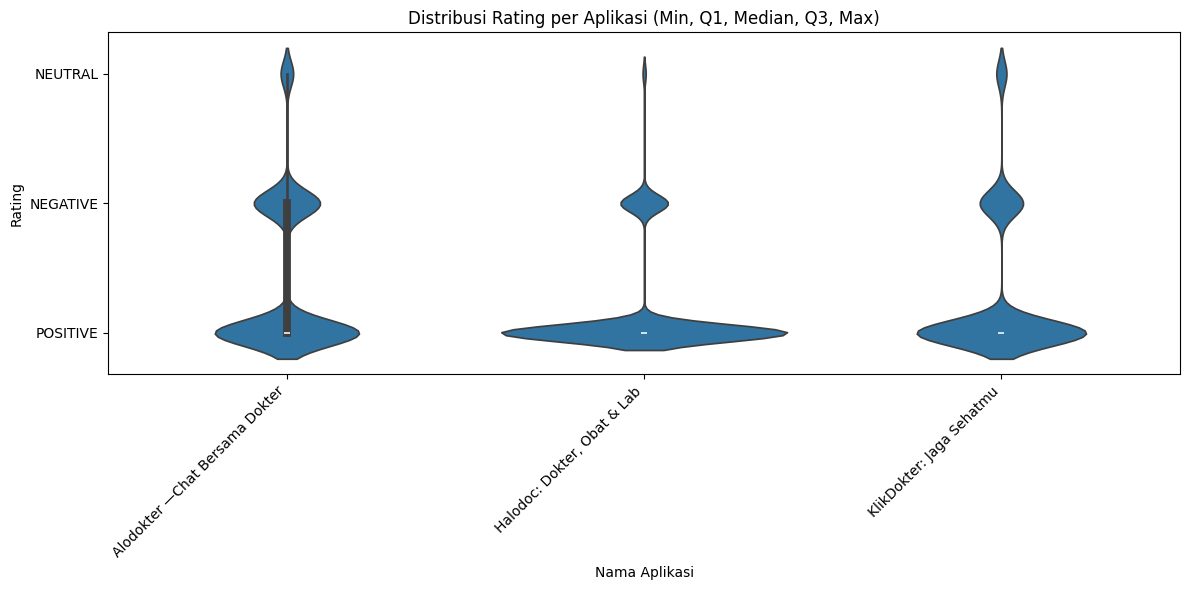

In [20]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='app_name', y='sentiment')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### A.3.1 (!!REVIEW THIS!!) Inspecting Neutral Sentiment

In [21]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [22]:
df.groupby('app_name')['sentiment'].value_counts()

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

In [23]:
df.columns

Index(['platform', 'app_name', 'rating', 'review', 'sentiment', 'weight',
       'orig_id', 'review_character_length', 'review_word_count'],
      dtype='object')

In [24]:
temp = df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')]
pd.set_option("display.max_colwidth", None)
display(temp[['weight', 'review', 'rating', 'sentiment']])



,weight,review,rating,sentiment
0,UNINFORMATIVE,oke,5,NEUTRAL
4,UNINFORMATIVE,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",5,NEUTRAL
8,UNINFORMATIVE,good job,5,NEUTRAL
10,UNINFORMATIVE,ok,5,NEUTRAL
12,UNINFORMATIVE,baik,4,NEUTRAL
...,...,...,...,...
9408,UNINFORMATIVE,blngapa,5,NEUTRAL
9423,UNINFORMATIVE,cari tau tentang kesehatan.,4,NEUTRAL
9427,UNINFORMATIVE,Apa salep aman anti septik buat bisul?,5,NEUTRAL
9558,INFORMATIVE,Anak saya udah 10 hari tapi badannya masih panas dan klu panas kakinya terasa dingin dan tangannya juga dingin minumin parasetamol dan amozsilin masih turun naik panasnya apa masalahnya dan apa obat yang bagus? . Apa obat yang bagus buat penderita tipes,5,NEUTRAL


In [25]:
pd.set_option("display.max_colwidth", 100)

### A.4 Rating score overview 
based on each App review

In [26]:
df.groupby('app_name')['rating'].describe().T

app_name,Alodokter —Chat Bersama Dokter,"Halodoc: Dokter, Obat & Lab",KlikDokter: Jaga Sehatmu
count,7602.000000,7295.000000,4783.000000
mean,3.830571,4.426456,4.133807
std,1.696626,1.297648,1.468074
min,1.000000,1.000000,1.000000
25%,2.000000,5.000000,4.000000
50%,5.000000,5.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


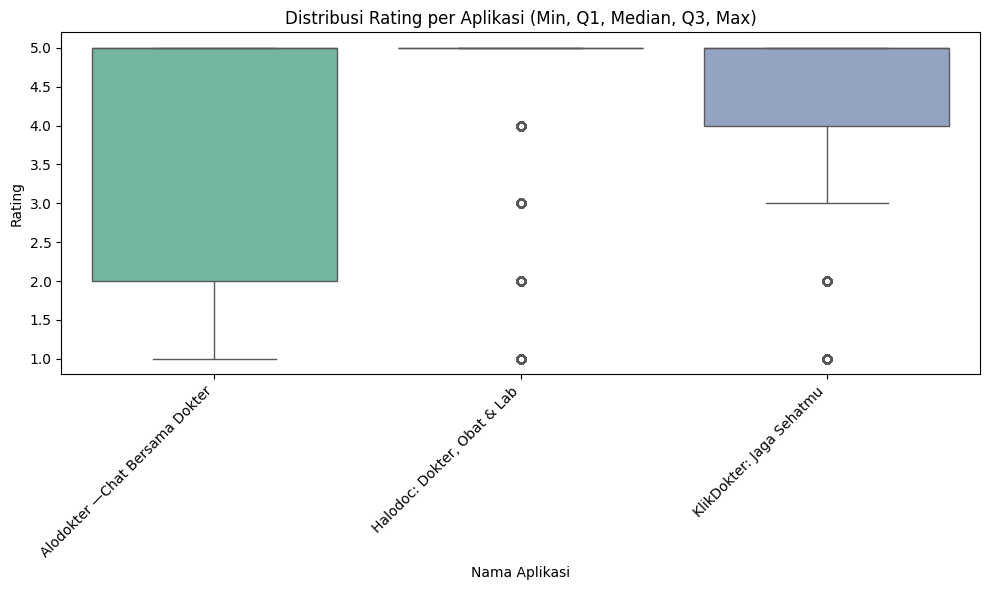

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='app_name', y='rating', palette='Set2')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### A.5 Potential Anomaly

In [28]:
df[(df['sentiment'] == 'NEGATIVE') & (df['rating'] > 3)]

,platform,app_name,rating,review,sentiment,weight,orig_id,review_character_length,review_word_count
9,Play Store,Alodokter —Chat Bersama Dokter,5,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau...",NEGATIVE,INFORMATIVE,9,148.0,25.0
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli GK d kirim obat buat kesembuhan ngirim nya sembrono,NEGATIVE,INFORMATIVE,16,98.0,18.0
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kembali waktu daftar,kayak ngambil data ajaaa.",NEGATIVE,INFORMATIVE,29,88.0,13.0
40,Play Store,Alodokter —Chat Bersama Dokter,4,gak ada pembayaran lewat E-walet dana,NEGATIVE,UNINFORMATIVE,40,37.0,6.0
68,Play Store,Alodokter —Chat Bersama Dokter,5,"jangan mau berlangganan ,pembohong katanya unlimited tapi tetap di batasi,,maunya aplikasi ini k...",NEGATIVE,INFORMATIVE,68,323.0,45.0
...,...,...,...,...,...,...,...,...,...
17952,Play Store,KlikDokter: Jaga Sehatmu,4,Waktu konsultasi kurang lama.,NEGATIVE,INFORMATIVE,17952,29.0,4.0
18858,Play Store,KlikDokter: Jaga Sehatmu,4,"saya sudah daftar ,tapi kode verifikasi tidak di kirim kirim.",NEGATIVE,UNINFORMATIVE,18858,61.0,10.0
19035,Play Store,KlikDokter: Jaga Sehatmu,4,tlng jwbany lbih dipejlas,NEGATIVE,INFORMATIVE,19035,25.0,4.0
19292,Play Store,KlikDokter: Jaga Sehatmu,5,Koyok taek,NEGATIVE,UNINFORMATIVE,19292,10.0,2.0


### A.6 Sentiment x Weight overview

In [29]:
# 1. Sentiment x weight
print(pd.crosstab(df['sentiment'], df['weight'], margins=True))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE    All
sentiment                                            
NEGATIVE       213         1223           2785   4221
NEUTRAL         40          104            567    711
POSITIVE       137         1391          13220  14748
All            390         2718          16572  19680


In [30]:
print(pd.crosstab(df['sentiment'], df['weight'], normalize='columns').round(3))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE
sentiment                                     
NEGATIVE     0.546        0.450          0.168
NEUTRAL      0.103        0.038          0.034
POSITIVE     0.351        0.512          0.798


In [31]:
# 2. Weight per aplikasi
print(pd.crosstab(df['app_name'], df['weight'], normalize='index').round(3))

weight                          COMPLEX  INFORMATIVE  UNINFORMATIVE
app_name                                                           
Alodokter —Chat Bersama Dokter    0.022        0.137          0.842
Halodoc: Dokter, Obat & Lab       0.017        0.121          0.862
KlikDokter: Jaga Sehatmu          0.021        0.167          0.812


In [32]:
print(df.groupby('weight')['review_word_count'].describe())

                 count       mean        std  min   25%   50%   75%    max
weight                                                                    
COMPLEX          390.0  47.866667  18.721684  8.0  33.0  45.0  63.0   89.0
INFORMATIVE     2718.0  30.149375  16.189954  2.0  18.0  26.0  37.0  111.0
UNINFORMATIVE  16520.0   7.930872   6.737514  1.0   3.0   6.0  11.0   90.0


In [33]:
# 4. Weight di hard subset
hard = df[
    (df['sentiment'] == 'NEUTRAL') |
    ((df['sentiment'] == 'NEGATIVE') & (df['rating'] >= 4)) |
    ((df['sentiment'] == 'POSITIVE') & (df['rating'] <= 2))
]
print(pd.crosstab(hard['sentiment'], hard['weight']))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE
sentiment                                     
NEGATIVE        22           52             76
NEUTRAL         40          104            567
POSITIVE         4           19             44


In [34]:
print(f"Review length dist: \n{df['review_character_length'].describe()}")

Review length dist: 
count    19628.000000
mean        76.729264
std         81.154154
min          2.000000
25%         25.000000
50%         48.000000
75%         98.000000
max        595.000000
Name: review_character_length, dtype: float64


In [35]:
neg_words = {'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tapi', 'tetapi', 'namun'}

def has_neg(text):
    return any(t in neg_words for t in str(text).lower().split())

df['has_neg'] = df['review'].map(has_neg)
print(df['has_neg'].mean())                                # proporsi review yang kehilangan negasi
print(df.groupby('sentiment')['has_neg'].mean().round(3))  # per kelas

0.1410569105691057
sentiment
NEGATIVE    0.410
NEUTRAL     0.159
POSITIVE    0.063
Name: has_neg, dtype: float64


## B. Text Cleaning & Normalizing

In [36]:
from pathlib import Path
import sys, os
import ftfy
from sklearn.model_selection import StratifiedGroupKFold

ROOT_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT_DIR))
'''
from config.config_script import RAW_DATA_DIR, DEFAULT_NORM_DICT, WEIGHTED_SPLIT_DATA_DIR 
from src.preprocessing_paper2 import TextPreprocessing_Paper2
'''

'\nfrom config.config_script import RAW_DATA_DIR, DEFAULT_NORM_DICT, WEIGHTED_SPLIT_DATA_DIR \nfrom src.preprocessing_paper2 import TextPreprocessing_Paper2\n'

### B.1 Freeze The Split

In [37]:

# Path settings
SPLIT_DIR = Path('../data/splits')
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = SPLIT_DIR / 'split_ids.csv'

# Function for Stratified Group Split
def split_stratified_group(y, groups, test_size=0.10, random_state=42):
    n_splits = max(2, int(round(1.0 / test_size)))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    train_idx, test_idx = next(sgkf.split(y, y, groups))
    return train_idx, test_idx

# Create split_ids.csv only if it does not exist yet
if not SPLIT_FILE.exists():
    print("Creating frozen split_ids.csv\n")

    raw = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', keep_default_na=False, low_memory=False)
    raw["orig_id"] = raw.index
    
    # Remove empty reviews (the 52 missing rows)
    raw = raw[raw["review"].astype(str).str.strip() != ""].copy()
    
    # Create group key from raw text
    raw["group_key"] = (
        raw["review"]
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )
    
    # Stratify by both sentiment and weight
    raw["strata"] = raw["sentiment"].astype(str) + "|" + raw["weight"].astype(str)
    
    # Split 10% test
    rest_idx, test_idx = split_stratified_group(
        y=raw["strata"],
        groups=raw["group_key"],
        test_size=0.10,
        random_state=42
    )
    
    # Split 20% validation from the remaining 90% (20 / 90)
    raw_rest = raw.iloc[rest_idx].copy()
    train_sub_idx, val_sub_idx = split_stratified_group(
        y=raw_rest["strata"],
        groups=raw_rest["group_key"],
        test_size=(0.20 / 0.90),
        random_state=42
    )
    
    # Assign split labels
    raw["split"] = "train"
    raw.iloc[test_idx, raw.columns.get_loc("split")] = "test"
    raw.iloc[rest_idx[val_sub_idx], raw.columns.get_loc("split")] = "val"
    raw[["orig_id", "split"]].to_csv(SPLIT_FILE, index=False)
    print("split_ids.csv created and saved\n")
else:
    print(f"{SPLIT_FILE} already exists. Using existing file.")

splits = pd.read_csv(SPLIT_FILE)

print("Data distribution:")
print(splits["split"].value_counts(normalize=True) * 100)

../data/splits/split_ids.csv already exists. Using existing file.
Data distribution:
split
train    67.668637
val      22.243733
test     10.087630
Name: proportion, dtype: float64


### B.1 Cleaning & Normalizing

#### Checking Duplicates after Using Raw file

In [38]:
df = df.dropna(subset=["review"]).copy()
df["group_key"] = (
    df["review"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

sent_conflicts = df.groupby("group_key")["sentiment"].nunique()
weight_conflicts = df.groupby("group_key")["weight"].nunique()

num_sent_conflicts = (sent_conflicts > 1).sum()
num_weight_conflicts = (weight_conflicts > 1).sum()

print(f"Total unique texts: {len(sent_conflicts):,}")
print(f"Texts with conflicting sentiment: {num_sent_conflicts:,} ({num_sent_conflicts / len(sent_conflicts) * 100:.2f}%)")
print(f"Texts with conflicting weight:    {num_weight_conflicts:,} ({num_weight_conflicts / len(weight_conflicts) * 100:.2f}%)")

# 3. Count total rows affected by sentiment conflicts
conflict_sent_keys = sent_conflicts[sent_conflicts > 1].index
conflict_rows = df[df["group_key"].isin(conflict_sent_keys)]
print(f"Total rows with sentiment conflicts: {len(conflict_rows):,} ({len(conflict_rows) / len(df) * 100:.2f}% of all data)")

# 4. Show top 10 most frequent conflicting texts
print("\nTop 10 conflicting texts by count:")
top_conflict_keys = conflict_rows["group_key"].value_counts().head(10).index

for text in top_conflict_keys:
    subset = conflict_rows[conflict_rows["group_key"] == text]
    counts = subset["sentiment"].value_counts().to_dict()
    print(f"- '{text}' ({len(subset)} rows): {counts}")

Total unique texts: 18,373
Texts with conflicting sentiment: 41 (0.22%)
Texts with conflicting weight:    2 (0.01%)
Total rows with sentiment conflicts: 174 (0.89% of all data)

Top 10 conflicting texts by count:
- 'mantap' (17 rows): {'POSITIVE': 16, 'NEGATIVE': 1}
- 'good' (15 rows): {'POSITIVE': 13, 'NEUTRAL': 2}
- 'nice' (9 rows): {'POSITIVE': 5, 'NEUTRAL': 4}
- 'sangat baik' (8 rows): {'POSITIVE': 7, 'NEGATIVE': 1}
- 'good job' (8 rows): {'POSITIVE': 7, 'NEUTRAL': 1}
- 'baik' (7 rows): {'NEUTRAL': 4, 'POSITIVE': 3}
- 'terimakasih' (7 rows): {'POSITIVE': 5, 'NEUTRAL': 2}
- 'ok' (7 rows): {'POSITIVE': 4, 'NEUTRAL': 3}
- 'oke' (6 rows): {'NEUTRAL': 5, 'POSITIVE': 1}
- 'sngat membantu' (6 rows): {'POSITIVE': 5, 'NEGATIVE': 1}


### B.2 Creating a cleaner DataFrame

In [40]:
import re
import warnings
import pandas as pd
import emoji
from pathlib import Path

class TextPreprocessing:

    def __init__(self, df, split_file="../data/splits/split_ids.csv"):
        self.df = df.copy()
        self.split_file = Path(split_file)
        self._EMOJI = re.compile(r"[\U0001F000-\U0001FAFF☀-➿]")
        self._warned_emoji = False

    def _fix_mojibake_step(self):
        """Fix encoding errors and create 'review_cleaned'."""
        self.df["review_cleaned"] = (
            self.df["review"].astype(str).apply(ftfy.fix_text)
        )

    def _convert_emoji_single(self, text: str) -> str:
        if not isinstance(text, str) or not self._EMOJI.search(text):
            return str(text)
        try:

            def _repl(chars, data):
                name = data.get("id") or data.get("en") or ""
                return " emoji " + name.strip(":").replace("_", " ") + " "

            return emoji.replace_emoji(text, replace=_repl)
        except Exception:
            if not self._warned_emoji:
                warnings.warn(f"[ERROR] fail to convert emoji into text: {text}")
                self._warned_emoji = True
            return text

    def _convert_emoji(self):
        self.df["review_cleaned"] = self.df["review_cleaned"].apply(
            self._convert_emoji_single
        )

    def _clean(self):
        self.df["review_cleaned"] = (
            self.df["review_cleaned"]
            .str.lower()
            .str.replace(r"[^\w\s]", " ", regex=True)
            .str.replace(r"\d+", "", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    def _norm_dict(self):
        try:
            from config.config_script import DEFAULT_NORM_DICT

            norm_dict = DEFAULT_NORM_DICT
        except ImportError:
            norm_dict = {}

        self.df["review_cleaned_normed"] = self.df["review_cleaned"].apply(
            lambda text: " ".join(norm_dict.get(w, w) for w in text.split())
        )

    def _merge_frozen_split(self):
        split_cols = [c for c in self.df.columns if c.startswith("split")]
        self.df = self.df.drop(columns=split_cols, errors="ignore")

        splits = pd.read_csv(self.split_file)
        n_before = len(self.df)
        self.df = self.df.merge(
            splits, on="orig_id", how="inner", validate="one_to_one"
        )
        print(
            f"Rows before merge: {n_before:,}, after: {len(self.df):,} "
            f"(removed {n_before - len(self.df):,} not in split file)"
        )
        assert self.df["split"].notna().all()

    def _organize_column(self):
        self.df = self.df[[
            "orig_id",
            "app_name",
            "rating",
            "sentiment",
            "review_cleaned_normed",
            "weight",
            "has_neg",
            "split",
        ]]

    def fit_transform(self, df=None):
        if df is not None:
            self.df = df.copy()

        if "orig_id" not in self.df.columns:
            self.df["orig_id"] = self.df.index

        # Remove rows without review text
        self.df = self.df.dropna(subset=["review"]).copy()

        # 1. Fix encoding errors first (this creates self.df['review_cleaned'])
        self._fix_mojibake_step()

        # 2. Convert emoji characters
        self._convert_emoji()

        # 3. Clean symbols and spaces
        self._clean()

        # 4. Normalize words using dictionary
        self._norm_dict()

        # 5. Join split file and select columns
        self._merge_frozen_split()
        self._organize_column()

        # Slice datasets
        self.train_df = self.df[self.df["split"] == "train"].copy()
        self.val_df = self.df[self.df["split"] == "val"].copy()
        self.test_df = self.df[self.df["split"] == "test"].copy()

        return self.df, self.train_df, self.val_df, self.test_df


# Run preprocessing with frozen split
df_final, train_df, val_df, test_df = TextPreprocessing(df).fit_transform()

# Check row counts
print("Split counts:")
print(f"Train : {len(train_df):,} rows ({len(train_df)/len(df_final)*100:.2f}%)")
print(f"Val   : {len(val_df):,} rows ({len(val_df)/len(df_final)*100:.2f}%)")
print(f"Test  : {len(test_df):,} rows ({len(test_df)/len(df_final)*100:.2f}%)")
print(f"Total : {len(df_final):,} rows")

ROOT DIR: /home/sunsun/Documents/Semester5/telemedicine-sentiment-analysis-MTL
Rows before merge: 19,628, after: 19,628 (removed 0 not in split file)
Split counts:
Train : 13,282 rows (67.67%)
Val   : 4,366 rows (22.24%)
Test  : 1,980 rows (10.09%)
Total : 19,628 rows


### B.3 Fixing Mojibake

In [41]:
import ftfy

def fix_mojibake(text: str) -> str:
    """Fix corrupted characters caused by encoding errors."""
    if not isinstance(text, str):
        return text
    return ftfy.fix_text(text)

def mojibake_report(df: pd.DataFrame, text_col: str = "review", sample_size: int = 5):
    """
    Check for mojibake in the review column.
    Reports the number of affected rows and shows examples.
    """
    # Exclude missing values
    valid_reviews = df[df[text_col].notna()].copy()
    
    # Check if the fixed text is different from the original text
    fixed_series = valid_reviews[text_col].astype(str).apply(fix_mojibake)
    mask = valid_reviews[text_col].astype(str) != fixed_series
    
    affected_count = mask.sum()
    total_valid = len(valid_reviews)
    percentage = (affected_count / total_valid) * 100
    
    print(f"Total valid reviews checked: {total_valid:,}")
    print(f"Rows affected by mojibake: {affected_count:,} ({percentage:.2f}%)")
    
    if affected_count > 0:
        print(f"\nShowing up to {sample_size} sample fixes:")
        sample_indices = valid_reviews[mask].index[:sample_size]
        for idx in sample_indices:
            orig = valid_reviews.loc[idx, text_col]
            fixed = fixed_series.loc[idx]
            print(f"- Row {idx}:")
            print(f"  Raw   : {orig}")
            print(f"  Fixed : {fixed}\n")
    else:
        print("\nNo mojibake found.")
        
    return mask

In [42]:
# Drop empty reviews first as established
df = df.dropna(subset=["review"]).copy()

# Run the report
affected_mask = mojibake_report(df, text_col="review")

Total valid reviews checked: 19,628
Rows affected by mojibake: 587 (2.99%)

Showing up to 5 sample fixes:
- Row 51:
  Raw   : dr.Merry sangat teliti mendiagnosa, dan sangat responsif, ðŸ½ðŸ½ðŸ½
  Fixed : dr.Merry sangat teliti mendiagnosa, dan sangat responsif, 🏽🏽🏽

- Row 120:
  Raw   : Terimakasih banyak dok atas sarannya. ðŸ»ðŸ»
  Fixed : Terimakasih banyak dok atas sarannya. 🏻🏻

- Row 126:
  Raw   : sabar dan baik bangett ï¸
  Fixed : sabar dan baik bangett ️

- Row 181:
  Raw   : merasa nyamanï¸
  Fixed : merasa nyaman️

- Row 202:
  Raw   : gimana sih pengiriman obat 1 jam tpi blm di kirimÂ² juga, mana yang kata nya 1 jam sampe, kalau nggk niat krja jaga apotik Yaudh nggk usah krja, kan kasihan orang yg sakit butuh obatnya jdi nunggu lama,, udh 2x begini ternyata tidk ada perubahan ,, tolong dong take down aja ni aplikasi alodokter nya, percuma ada kalau tidk sesuai yg tertulis, kata nya pengiriman obat 1 jam sampe, mana nggk ada lama bnget.
  Fixed : gimana sih pengiriman 

In [ ]:
def fit_transform(self, df: pd.DataFrame = None):
    if df is not None:
        self.df = df.copy()

    if "orig_id" not in self.df.columns:
        self.df["orig_id"] = self.df.index

    self.df = self.df.dropna(subset=["review"]).copy()

    # 1. Fix encoding/mojibake first
    self._fix_mojibake_step()

    # 2. Convert emoji to tokens next
    self._convert_emoji()

    # 3. Text cleaning & normalization
    self._clean()
    self._norm_dict()

    # 4. Splits and column selection
    self._merge_frozen_split()
    self._organize_column()

    self.train_df = self.df[self.df["split"] == "train"].copy()
    self.val_df = self.df[self.df["split"] == "val"].copy()
    self.test_df = self.df[self.df["split"] == "test"].copy()

    return self.df, self.train_df, self.val_df, self.test_df

In [43]:
test_indices = [51, 120, 202]
check_df = df_final[df_final["orig_id"].isin(test_indices)]
display(check_df[["orig_id", "review_cleaned_normed", "sentiment", "weight"]])

,orig_id,review_cleaned_normed,sentiment,weight
51,51,dari merry sangat teliti mendiagnosa dan sangat responsif emoji medium skin tone emoji medium sk...,POSITIVE,UNINFORMATIVE
120,120,terimakasih banyak dok atas sarannya emoji light skin tone emoji light skin tone,POSITIVE,UNINFORMATIVE
202,202,bagaimana sih pengiriman obat jam tpi belum di kirim² juga mana yang kata nya jam sampai kalau n...,NEGATIVE,INFORMATIVE


In [46]:
emoji_mask = df_final["review_cleaned_normed"].str.contains(r"\bemoji\b", na=False)

total_emoji_rows = emoji_mask.sum()
total_rows = len(df_final)
percentage = (total_emoji_rows / total_rows) * 100

print(f"Total rows: {total_rows:,}")
print(f"Rows with emoji: {total_emoji_rows:,} ({percentage:.2f}%)")

# 2. View 5 converted examples (Original vs Converted)
print("\nSample converted reviews:")
sample_indices = df_final[emoji_mask]["orig_id"].head(5)

for orig_id in sample_indices:
    raw_text = df.loc[df["orig_id"] == orig_id, "review"].values[0]
    cleaned_text = df_final.loc[df_final["orig_id"] == orig_id, "review_cleaned_normed"].values[0]
    print(f"\n- Row {orig_id}:")
    print(f"  Raw      : {raw_text}")
    print(f"  Converted: {cleaned_text}")

Total rows: 19,628
Rows with emoji: 203 (1.03%)

Sample converted reviews:

- Row 51:
  Raw      : dr.Merry sangat teliti mendiagnosa, dan sangat responsif, ðŸ½ðŸ½ðŸ½
  Converted: dari merry sangat teliti mendiagnosa dan sangat responsif emoji medium skin tone emoji medium skin tone emoji medium skin tone

- Row 120:
  Raw      : Terimakasih banyak dok atas sarannya. ðŸ»ðŸ»
  Converted: terimakasih banyak dok atas sarannya emoji light skin tone emoji light skin tone

- Row 374:
  Raw      : Maaf banget, alodok. Untuk acne fighter seperti ku. BEBERAPA dr. terlalu teoritis. Mereka terlalu menganggap kondisi pasien itu secara umum. bukan personal. mereka SAMA SEKALI tidak mendengarkan keluhan pasien. Kalau keluhannya A, dikasih pendekatan B. Padahal mereka ini spKK, Spdve, harusnya sudah memiliki banyak pengalaman tiap individu. Aku memang bukan ahli medis, tapi harusnya berakal dulu baru berilmu. karena ilmu tidak akan ada artinya jika tidak berakalðŸ»
  Converted: maaf banget alod

### Reruning the duplicates 
Why?
1. Before the fix, two reviews might have had the exact same meaning, but different text errors
2. Fake duplicates were removed
3. Accurate label conflict metrics

In [45]:
# Create group_key on the cleaned & normalized text
df_final["group_key"] = (
    df_final["review_cleaned_normed"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

sent_conflicts = df_final.groupby("group_key")["sentiment"].nunique()
weight_conflicts = df_final.groupby("group_key")["weight"].nunique()

num_sent_conflicts = (sent_conflicts > 1).sum()
num_weight_conflicts = (weight_conflicts > 1).sum()

print(f"Total unique texts: {len(sent_conflicts):,}")
print(f"Texts with conflicting sentiment: {num_sent_conflicts:,} ({num_sent_conflicts / len(sent_conflicts) * 100:.2f}%)")
print(f"Texts with conflicting weight:    {num_weight_conflicts:,} ({num_weight_conflicts / len(weight_conflicts) * 100:.2f}%)")

conflict_sent_keys = sent_conflicts[sent_conflicts > 1].index
conflict_rows = df_final[df_final["group_key"].isin(conflict_sent_keys)]
print(f"Total rows with sentiment conflicts: {len(conflict_rows):,} ({len(conflict_rows) / len(df_final) * 100:.2f}% of data)")

# 4. Show top 10 most frequent conflicting texts
print("\nTop 10 conflicting texts by count:")
top_conflict_keys = conflict_rows["group_key"].value_counts().head(10).index

for text in top_conflict_keys:
    subset = conflict_rows[conflict_rows["group_key"] == text]
    counts = subset["sentiment"].value_counts().to_dict()
    print(f"- '{text}' ({len(subset)} rows): {counts}")

Total unique texts: 17,968
Texts with conflicting sentiment: 46 (0.26%)
Texts with conflicting weight:    2 (0.01%)
Total rows with sentiment conflicts: 268 (1.37% of data)

Top 10 conflicting texts by count:
- 'mantap' (26 rows): {'POSITIVE': 25, 'NEGATIVE': 1}
- 'bagus' (26 rows): {'POSITIVE': 25, 'NEGATIVE': 1}
- 'terima kasih' (22 rows): {'POSITIVE': 21, 'NEUTRAL': 1}
- 'good' (20 rows): {'POSITIVE': 17, 'NEUTRAL': 3}
- 'bagus sangat membantu' (13 rows): {'POSITIVE': 12, 'NEUTRAL': 1}
- 'nice' (10 rows): {'NEUTRAL': 5, 'POSITIVE': 5}
- 'terimakasih' (10 rows): {'POSITIVE': 8, 'NEUTRAL': 2}
- 'baik' (10 rows): {'NEUTRAL': 5, 'POSITIVE': 5}
- 'ok' (9 rows): {'POSITIVE': 5, 'NEUTRAL': 4}
- 'sangat baik' (8 rows): {'POSITIVE': 7, 'NEGATIVE': 1}


### B.4 Test Area

In [ ]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

nltk_sw = set(stopwords.words('indonesian'))
sastrawi_sw = set(StopWordRemoverFactory().get_stop_words())

keep = ['tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tapi', 'tetapi',
        'namun', 'padahal', 'sangat', 'sekali', 'lebih', 'tanpa']

print("NLTK:", len(nltk_sw), [w for w in keep if w in nltk_sw])
print("Sastrawi:", len(sastrawi_sw), [w for w in keep if w in sastrawi_sw])

ModuleNotFoundError: No module named 'nltk'

## C. Text Representation & Modelling

In [ ]:
LABELS = df_final['sentiment'].unique().tolist()
LABELS

['NEUTRAL', 'NEGATIVE', 'POSITIVE']

In [ ]:
df_final['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7586
Halodoc: Dokter, Obat & Lab       7281
KlikDokter: Jaga Sehatmu          4761
Name: count, dtype: int64

In [ ]:
train_df.head(10)

,app_name,rating,sentiment,review_cleaned_normed,weight,has_neg,split
2,Alodokter —Chat Bersama Dokter,1,NEGATIVE,mending chat sama chatgpt dari pada alodokter tidak bisa keluarin surat dokter gara abis katanya...,UNINFORMATIVE,False,train
3,Alodokter —Chat Bersama Dokter,5,POSITIVE,sangat memuaskan,UNINFORMATIVE,False,train
4,Alodokter —Chat Bersama Dokter,5,NEUTRAL,saya usia tahun sering sakit gigi kalau sakit saya minum obat oskadon sembuh lama kemudian sekar...,UNINFORMATIVE,True,train
5,Alodokter —Chat Bersama Dokter,2,NEGATIVE,dokternya responnya lama semoga bisa diperbaiki ya dok responnya terimkasih semangat terus,UNINFORMATIVE,False,train
6,Alodokter —Chat Bersama Dokter,5,POSITIVE,bisa bertanya tentang kesehat,UNINFORMATIVE,False,train
7,Alodokter —Chat Bersama Dokter,5,POSITIVE,petunjuk dokter dan konsultasi menenangkan hati,UNINFORMATIVE,False,train
8,Alodokter —Chat Bersama Dokter,5,NEUTRAL,good job,UNINFORMATIVE,False,train
10,Alodokter —Chat Bersama Dokter,5,NEUTRAL,ok,UNINFORMATIVE,False,train
11,Alodokter —Chat Bersama Dokter,1,NEGATIVE,syaa sudah konsul dokter sp m di kasih resep obat tapi ketika saya mau beli d alloshop tidak bis...,INFORMATIVE,True,train
14,Alodokter —Chat Bersama Dokter,2,NEUTRAL,saya mau tanya apa obat yang paling aman untuk penyakit tulang ekor yang kegeser akibat dari jat...,UNINFORMATIVE,False,train


### C.1 TF-IDF + SVM

In [ ]:
import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer

max_features = 150000
ngram_range = (1, 2)

train_df = train_df.dropna()
test_df = test_df.dropna()

raw_vocab_train = set(" ".join(train_df['review_cleaned_normed']).split())
raw_vocab_val = set(" ".join(val_df['review_cleaned_normed']).split())
raw_vocab_test = set(" ".join(test_df['review_cleaned_normed']).split())

vec_train = TfidfVectorizer(max_features = max_features, ngram_range=ngram_range)
vec_train.fit(train_df['review_cleaned_normed'])

vec_val = TfidfVectorizer(max_features = max_features, ngram_range=ngram_range)
vec_val.fit(val_df['review_cleaned_normed'])

vec_test = TfidfVectorizer(max_features = max_features, ngram_range=ngram_range)
vec_test.fit(test_df['review_cleaned_normed'])

vec_fit_train = vec_train.get_feature_names_out()
vec_fit_val = vec_val.get_feature_names_out()
vec_fit_test = vec_test.get_feature_names_out()

print("Train, Val, Test Vocabulary size:")
print("raw \t\t\t:", len(raw_vocab_train), ',', len(raw_vocab_val), ',', len(raw_vocab_test))
print("TF-IDF n-gram (1, 2)\t:", len(vec_fit_train), ',', len(vec_fit_val), ',', len(vec_fit_test))

vec_full = TfidfVectorizer(max_features=max_features, ngram_range=ngram_range)
train_full_vocab = set(vec_full.fit(train_df['review_cleaned_normed']).get_feature_names_out())
val_full_vocab = set(vec_full.fit(val_df['review_cleaned_normed']).get_feature_names_out())
test_full_vocab = set(vec_full.fit(test_df['review_cleaned_normed']).get_feature_names_out())

vec_full.fit(df_final['review_cleaned_normed'])
fitted_vocab = set(vec_full.get_feature_names_out())

oov_val = val_full_vocab - train_full_vocab
oov_test = test_full_vocab - train_full_vocab

print(f"OOV compared to Train:")
print(f"Train vs Val (OOV) : {len(oov_val):,} ({len(oov_val)/len(val_full_vocab)*100:.2f}% compared to Val)")
print(f"Train vs Test(OOV) : {len(oov_test):,} ({len(oov_test)/len(test_full_vocab)*100:.2f}% compared to Test)")

print(f"\n - Total Vocabulary for full (train, val, test): {len(fitted_vocab)}")


Train, Val, Test Vocabulary size:
raw 			: 11232 , 5708 , 3599
TF-IDF n-gram (1, 2)	: 79974 , 33749 , 17674
OOV compared to Train:
Train vs Val (OOV) : 19,181 (56.83% compared to Val)
Train vs Test(OOV) : 8,806 (49.82% compared to Test)

 - Total Vocabulary for full (train, val, test): 107325


In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import joblib

class TFIDF_SVM_Baseline:
    """
    Class Baseline Sentiment Analysis menggunakan TF-IDF & Support Vector Machine (SVM).
    Mendukung Train, Validation, dan Test split.
    """
    
    def __init__(
        self,
        df_train,
        df_val,
        df_test,
        target_col='sentiment',
        text_col='review',
        max_features=5000,
        C=1.0,
        kernel='linear',
        random_state=42,
        weight_col='weight',
        sample_weight_map=None,
        class_weight='balanced'
    ):
        """
        Inisialisasi hyperparameter dan pemisahan data train, validation, & test
        """
        self.target_col = target_col
        self.text_col = text_col
        self.max_features = max_features
        self.C = C
        self.kernel = kernel
        self.random_state = random_state
        
        # Simpan dataframe mentah
        self.df_train = df_train.copy()
        self.df_val = df_val.copy()
        self.df_test = df_test.copy()
        
        # Penampung data fitur (TF-IDF) & target
        self.X_train_raw, self.X_val_raw, self.X_test_raw = None, None, None
        self.X_train, self.X_val, self.X_test = None, None, None
        
        self.y_train = self.df_train[self.target_col]
        self.y_val = self.df_val[self.target_col]
        self.y_test = self.df_test[self.target_col]

        self.weight_col = weight_col
        self.sample_weight_map = sample_weight_map

        # Inisialisasi model & vectorizer
        self.vectorizer = TfidfVectorizer(max_features=self.max_features, ngram_range=(1, 2))
        self.model = SVC(
            C=self.C,
            kernel=self.kernel,
            random_state=self.random_state,
            class_weight=class_weight
        )
        
        self.classes_ = np.unique(self.y_train)

    def _preprocess_text(self, text):
        """
        Lowercasing & pembersihan karakter khusus / angka
        """
        if not isinstance(text, str):
            return ""
        text = text.lower().strip()
        text = re.sub(r'[^a-z\s]', ' ', text)
        text = re.sub(r'\s+', ' ', text)
        return text

    def prepare_data(self):
        """
        Membersihkan teks pada Train, Validation, dan Test set
        """
        print("--> Preprocessing teks untuk Train, Validation, dan Test set...")
        
        # Drop missing values pada kolom ulasan & target jika ada
        self.df_train = self.df_train.dropna(subset=[self.text_col, self.target_col])
        self.df_val = self.df_val.dropna(subset=[self.text_col, self.target_col])
        self.df_test = self.df_test.dropna(subset=[self.text_col, self.target_col])

        def combine_text_and_weight(df):
                    clean_text = df[self.text_col].apply(self._preprocess_text)
                    weight_text = df["weight"].astype(str).str.lower()
                    return weight_text + " " + clean_text
        
        # Ekstrak & bersihkan teks
        self.X_train_raw = self.df_train[self.text_col].apply(self._preprocess_text)
        self.X_val_raw = self.df_val[self.text_col].apply(self._preprocess_text)
        self.X_test_raw = self.df_test[self.text_col].apply(self._preprocess_text)
        
        self.y_train = self.df_train[self.target_col]
        self.y_val = self.df_val[self.target_col]
        self.y_test = self.df_test[self.target_col]

        
        print(f"Data Siap! Train: {len(self.X_train_raw)} | Val: {len(self.X_val_raw)} | Test: {len(self.X_test_raw)}")

    def fit_transform_tfidf(self):
        """
        Fit TF-IDF pada Data Train, kemudian Transform Validation & Test
        """
        print("--> Mengubah Teks menjadi Matriks TF-IDF...")
        self.X_train = self.vectorizer.fit_transform(self.X_train_raw)
        self.X_val = self.vectorizer.transform(self.X_val_raw)
        self.X_test = self.vectorizer.transform(self.X_test_raw)
        
        print(f"Ukuran Matriks Fitur TF-IDF Train : {self.X_train.shape}")
        print(f"Ukuran Matriks Fitur TF-IDF Val   : {self.X_val.shape}")
        print(f"Ukuran Matriks Fitur TF-IDF Test  : {self.X_test.shape}")

    def train(self):
        """
        Melatih Model SVM menggunakan Data Train
        """
        sample_weight = None

        if self.sample_weight_map is not None:
            if self.weight_col not in self.df_train.columns:
                raise ValueError(
                    f"Kolom weight '{self.weight_col}' tidak ditemukan di data train."
                )

            raw_weights = self.df_train[self.weight_col]

            if raw_weights.isna().any():
                raise ValueError(
                    f"Kolom '{self.weight_col}' memiliki nilai kosong."
                )

            normalized_weights = raw_weights.astype(str).str.strip().str.upper()

            unknown = set(normalized_weights.unique()) - set(self.sample_weight_map)
            if unknown:
                raise ValueError(
                    f"Kategori weight belum dipetakan: {sorted(unknown)}"
                )

            sample_weight = normalized_weights.map(self.sample_weight_map).astype(float)

            if not np.isfinite(sample_weight.to_numpy()).all() or (sample_weight <= 0).any():
                raise ValueError("Semua sample weight harus berupa angka positif dan finite.")

            sample_weight = sample_weight.to_numpy()

        self.model.fit(
            self.X_train,
            self.y_train,
            sample_weight=sample_weight
        )
        
        print("Pelatihan Model SVM Selesai.")

    def evaluate(self, on='val'):
        """
        Evaluasi Performa Model pada Data Validation ('val') atau Test ('test')
        """
        if on == 'val':
            X_eval, y_true = self.X_val, self.y_val
            dataset_name = "VALIDATION SET"
        elif on == 'test':
            X_eval, y_true = self.X_test, self.y_test
            dataset_name = "TEST SET"
        else:
            raise ValueError("Parameter 'on' harus berisikan 'val' atau 'test'")

        print("\n" + "="*50)
        print(f"EVALUASI MODEL (SVM BASELINE) - {dataset_name}")
        print("="*50)
        
        y_pred = self.model.predict(X_eval)
        
        acc = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(y_true, y_pred, average='macro')
        
        print(f"Accuracy Score : {acc:.4f}")
        print(f"Macro F1-Score : {macro_f1:.4f}\n")
        
        print("Detailed Classification Report:")
        print(classification_report(y_true, y_pred))
        
        # Plot Confusion Matrix
        cm = confusion_matrix(y_true, y_pred, labels=self.classes_)
        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=self.classes_, yticklabels=self.classes_)
        plt.xlabel('Predicted Label')
        plt.ylabel('Actual Label')
        plt.title(f'Confusion Matrix - {dataset_name}')
        plt.tight_layout()
        plt.show()

    def predict_new(self, texts):
        """
        Fungsi Prediksi untuk Teks Baru
        """
        if isinstance(texts, str):
            texts = [texts]
        
        clean_texts = [self._preprocess_text(t) for t in texts]
        tfidf_features = self.vectorizer.transform(clean_texts)
        predictions = self.model.predict(tfidf_features)
        
        return list(zip(texts, predictions))

    def _fit_pipeline(self, model_path=None, vec_path=None, keep_model=False, final=False):
        self.prepare_data()

        self.fit_transform_tfidf()
        self.train()

        # Always evaluate validation set
        self.evaluate(on='val')

        # Evaluate test set only when final=True
        if final:
            self.evaluate(on='test')

        if keep_model and model_path and vec_path:
            self.save_model(model_path, vec_path)

    def save_model(self, model_path='svm_model.pkl', vec_path='tfidf_vectorizer.pkl'):
        """
        Menyimpan artifact vectorizer dan model ke file lokal
        """
        joblib.dump(self.model, model_path)
        joblib.dump(self.vectorizer, vec_path)
        print(f"Model berhasil disimpan di: {model_path} & {vec_path}")

In [ ]:
train_df.columns

Index(['app_name', 'rating', 'sentiment', 'review_cleaned_normed', 'weight',
       'has_neg', 'split'],
      dtype='object')

#### C.1.1 TFIDF with No Weight

c:\Users\Alvin\Music\Text Mining\TM & RM Project
--> Preprocessing teks untuk Train, Validation, dan Test set...
Data Siap! Train: 13248 | Val: 4417 | Test: 1963
--> Mengubah Teks menjadi Matriks TF-IDF...
Ukuran Matriks Fitur TF-IDF Train : (13248, 79415)
Ukuran Matriks Fitur TF-IDF Val   : (4417, 79415)
Ukuran Matriks Fitur TF-IDF Test  : (1963, 79415)
Pelatihan Model SVM Selesai.

EVALUASI MODEL (SVM BASELINE) - VALIDATION SET
Accuracy Score : 0.8990
Macro F1-Score : 0.6924

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.81      0.91      0.86       949
     NEUTRAL       0.28      0.27      0.28       160
    POSITIVE       0.96      0.93      0.94      3308

    accuracy                           0.90      4417
   macro avg       0.68      0.70      0.69      4417
weighted avg       0.90      0.90      0.90      4417



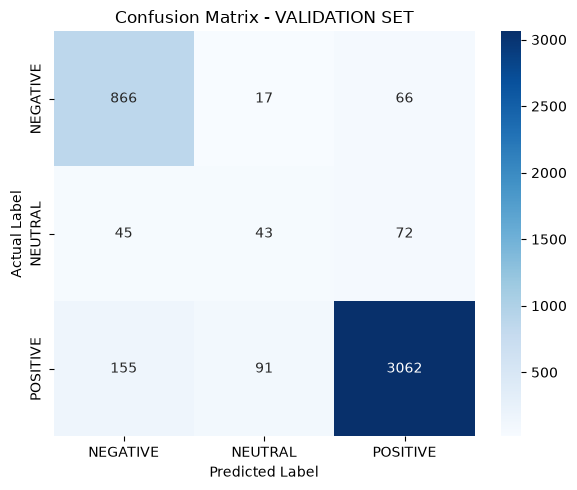


EVALUASI MODEL (SVM BASELINE) - TEST SET
Accuracy Score : 0.9103
Macro F1-Score : 0.7371

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.84      0.93      0.88       421
     NEUTRAL       0.34      0.42      0.38        71
    POSITIVE       0.97      0.93      0.95      1471

    accuracy                           0.91      1963
   macro avg       0.72      0.76      0.74      1963
weighted avg       0.92      0.91      0.91      1963



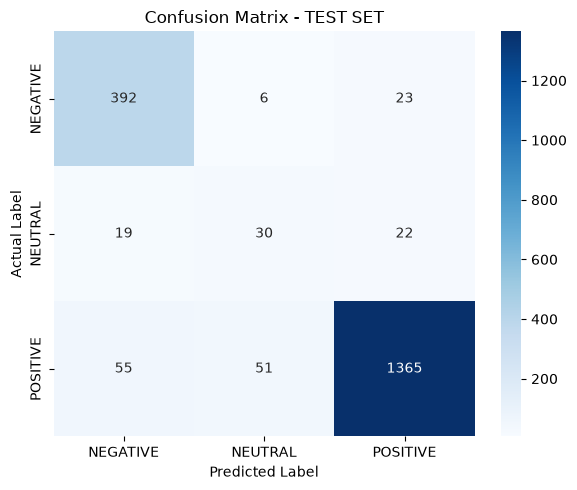

In [ ]:
import sys, os
from pathlib import Path

ROOT_DIR = Path().cwd().parent
print(ROOT_DIR)
sys.path.insert(0, str(ROOT_DIR))
from config.config_script import SVM_DIR, TFIDF_DIR

pipeline = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col='sentiment',
    text_col='review_cleaned_normed',
    max_features=100000,
    weight_col='weight',
    sample_weight_map=None
)._fit_pipeline(
    model_path = SVM_DIR, vec_path=TFIDF_DIR, keep_model = False
)



#### C.1.2 TFIDF + SVM with Weight

c:\Users\Alvin\Music\Text Mining\TM & RM Project
--> Preprocessing teks untuk Train, Validation, dan Test set...
Data Siap! Train: 13248 | Val: 4417 | Test: 1963
--> Mengubah Teks menjadi Matriks TF-IDF...
Ukuran Matriks Fitur TF-IDF Train : (13248, 79415)
Ukuran Matriks Fitur TF-IDF Val   : (4417, 79415)
Ukuran Matriks Fitur TF-IDF Test  : (1963, 79415)
Pelatihan Model SVM Selesai.

EVALUASI MODEL (SVM BASELINE) - VALIDATION SET
Accuracy Score : 0.9015
Macro F1-Score : 0.6917

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.83      0.91      0.87       949
     NEUTRAL       0.28      0.26      0.27       160
    POSITIVE       0.95      0.93      0.94      3308

    accuracy                           0.90      4417
   macro avg       0.69      0.70      0.69      4417
weighted avg       0.90      0.90      0.90      4417



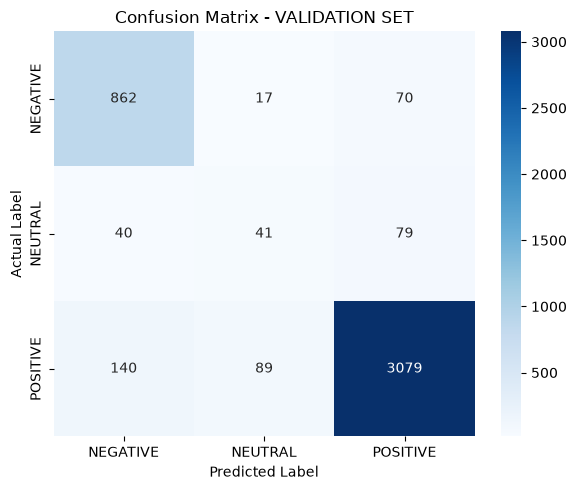


EVALUASI MODEL (SVM BASELINE) - TEST SET
Accuracy Score : 0.9109
Macro F1-Score : 0.7343

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.85      0.92      0.89       421
     NEUTRAL       0.34      0.41      0.37        71
    POSITIVE       0.96      0.93      0.95      1471

    accuracy                           0.91      1963
   macro avg       0.72      0.75      0.73      1963
weighted avg       0.92      0.91      0.91      1963



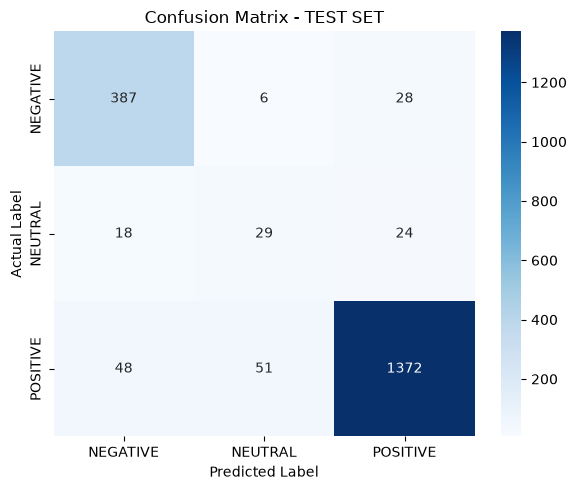

In [ ]:
import sys, os
from pathlib import Path

ROOT_DIR = Path().cwd().parent
print(ROOT_DIR)
sys.path.insert(0, str(ROOT_DIR))
from config.config_script import SVM_DIR, TFIDF_DIR

pipeline = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col='sentiment',
    text_col='review_cleaned_normed',
    max_features=100000,
    weight_col='weight',
    sample_weight_map={
        'COMPLEX': 3.0,
        'INFORMATIVE': 2.0,
        'UNINFORMATIVE': 1.0,
    }
)._fit_pipeline(
    model_path = SVM_DIR, vec_path=TFIDF_DIR
)



In [ ]:
stop()

NameError: name 'dwadawdadw' is not defined

### C.2 indoBERT

In [ ]:
from transformers import AutoTokenizer
model_tokenizer = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(model_tokenizer)
sample_text = df["review_cleaned_normed"].iloc[9]

inputs = tokenizer(
    sample_text,
    padding="max_length",  # Menyamakkan panjang urutan
    truncation=True,  # Memotong teks jika melebihi max_length
    max_length=128,  # Panjang maksimum token (biasanya 128 atau 256)
    return_tensors="pt",  # Mengembalikan format PyTorch Tensor
)

print(inputs["input_ids"])  # ID Angka untuk setiap token
print(inputs["attention_mask"])  # Masking untuk padding (1 untuk kata asli, 0 untuk padding)

tensor([[    2,  1339,    92,   119, 10651,   209,  4755,    34,  8189,   469,
            26,  2785, 10900,   406,  3526,  3109,   599,   119,   166,  2785,
           406,    92,   119,  3370,   176,  3511,  8189,     3,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,  

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(model_tokenizer)
raw_texts = df_final["review_cleaned_normed"].astype(str).tolist()

class IndoBERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts  = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )

        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels": torch.tensor(label, dtype=torch.long),
        }

train_df = df_final[df_final["split"] == "train"].reset_index(drop=True)
val_df = df_final[df_final["split"] == "val"].reset_index(drop=True)

train_dataset = IndoBERTDataset(
    train_df["review_cleaned_normed"].values,
    train_df["sentiment"].values,
    tokenizer,
)

val_dataset = IndoBERTDataset(
    val_df["review_cleaned_normed"].values, train_df["sentiment"].values, tokenizer
)

test_dataset = IndoBERTDataset(
    test_df["review_cleaned_normed"].values, train_df["sentiment"].values, tokenizer
)

train_loader = DataLoader(train_dataset, batch_size = 32, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
real_text = tokenizer.decode(inputs["input_ids"][0])
print(real_text)

[CLS] aplikasi ini tidak amanah saya order yang instan tapi di kirim esok hari aneh seharusnya kalau tidak bisa kirim hari ini tidak usah ada pengiriman instan [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [ ]:
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
tokens

['[CLS]',
 'aplikasi',
 'ini',
 'tidak',
 'amanah',
 'saya',
 'order',
 'yang',
 'instan',
 'tapi',
 'di',
 'kirim',
 'esok',
 'hari',
 'aneh',
 'seharusnya',
 'kalau',
 'tidak',
 'bisa',
 'kirim',
 'hari',
 'ini',
 'tidak',
 'usah',
 'ada',
 'pengiriman',
 'instan',
 '[SEP]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '

In [ ]:
unk_id = tokenizer.unk_token_id 
unk_count = (inputs["input_ids"] == unk_id).sum().item()
print(f"Jumlah token [UNK]: {unk_count}")

Jumlah token [UNK]: 0


INPUT_IDS DESCRIPTION:

- angka: 2 CLS -> Token khusus awal kalimat yang di auto-assign oleh indoBERT.

- Angka 1339, 92, 119, ...: Token ID untuk kata-kata dalam ulasanmu (misalnya "aplikasi", "bagus", "suka", dll).

- Deretan angka 0 di belakang: Token khusus [PAD] (padding). Karena kamu menetapkan max_length=128, sisa ruang kosong diisi angka 0 agar ukurannya pas 128 elemen.

- angka: 3 CLS -> Token khusus akhir kalimat yang di auto-assign oleh indoBERT.

ATTENTION MASK:
- 1 -> token asli
0 -> Token padding, diabaikan saat proses attention mechanism

In [ ]:
token_lengths = [
    len(tokenizer.encode(text, truncation=False))
    for text in df["review_cleaned_normed"]
]

print(pd.Series(token_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

count    19680.000000
mean        15.215752
std         14.272902
min          2.000000
50%         10.000000
90%         32.000000
95%         44.000000
99%         76.000000
max        125.000000
dtype: float64


set max_length = 125

In [ ]:
class indoBERT():
    def __init__(self, debug = True):
        self.label = df["sentiment"].unique()
        self.num_labels = len(df["sentiment"].unique())

        self.id2label = {0: "negative", 1: "neutral", 2: "positive"}
        self.label2id = {"negative": 0, "neutral": 1, "positive": 2}

        if debug == True:
            print(
                  f"id2label:\t{self.id2label}", "\n"
                  f"label2id:\t{self.label2id}"
            )

        from transformers import AutoModelForSequenceClassification
        from transformers import Trainer, TrainingArguments

        self.model = AutoModelForSequenceClassification.from_pretrained(
            model_tokenizer,
            num_labels=len(id2label),
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True,  # Mengabaikan perbedaan ukuran matriks bobot terakhir dari checkpoint lama
        )

        self.training_args = TrainingArguments(
            output_dir="./results",
            num_train_epochs=3,  # Biasanya 3-5 epoch cukup untuk fine-tuning BERT
            per_device_train_batch_size=32,
            per_device_eval_batch_size=32,
            learning_rate=2e-5,  # Learning rate kecil khusus Transformers (1e-5 s/d 5e-5)
            # evaluation_strategy="epoch",  # Evaluasi setiap selesai 1 epoch
            save_strategy="best",
            load_best_model_at_end=True,  # Simpan model dengan performa validation terbaik
            metric_for_best_model="f1_macro",  # Pakai F1-score sebagai acuan utama
            seed=42,
        )
        
        